# Pre-entrega 1 — Pipeline de entrenamiento, validación y clasificador base

**Proyecto Final — Data Science III (NLP & Deep Learning)** · **Autor:** Baltasar Santiago Galelli

## El problema

Un banco recibe miles de consultas de clientes por día: "mi tarjeta no llegó", "me rechazaron una transferencia", "¿por qué me cobraron esta comisión?". Hoy alguien las lee y las deriva al área que corresponde. El proyecto busca **clasificar automáticamente cada consulta según su motivo**, para derivarla al instante, medir qué problemas son más frecuentes y, en etapas posteriores, sugerir una respuesta.

**Dataset:** [Banking77](https://huggingface.co/datasets/PolyAI/banking77) (PolyAI, 2020): 13.083 consultas reales de clientes de un banco, en inglés, etiquetadas con **77 motivos**. Licencia CC BY 4.0.

## Esta entrega

El foco no está en el modelo sino en la **calidad del pipeline**: reproducible, con el dispositivo detectado automáticamente, un ciclo de entrenamiento explícito, validación en datos no vistos y métricas registradas por época. El clasificador es deliberadamente simple: texto representado con **TF-IDF** y un **MLP**. Las *embeddings* y los Transformers quedan para las próximas entregas, y este modelo va a ser la vara contra la que se comparen.

| Sección | Qué cubre |
|---|---|
| 1 | Entorno: librerías, semillas y dispositivo |
| 2 | Datos: descarga verificada, exploración y partición |
| 3 | Del texto a números: TF-IDF |
| 4 | Arquitectura: clasificador lineal y MLP (`nn.Module`) |
| 5 | Elección del learning rate |
| 6 | Entrenamiento y validación del modelo final |
| 7 | Comparación con el baseline lineal |
| 8 | Evaluación final en test y análisis de errores |
| 9 | Conclusiones |

El código vive en `src/pipeline/` y el mismo flujo corre sin notebook con `python scripts/entrenar.py`.

## 1. Entorno

Si el notebook se abre suelto en Colab, la primera celda clona el repositorio; después agrega `src/` al path. Colab ya trae PyTorch, scikit-learn y matplotlib: no se instala nada.

In [1]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/BaltaGalelli/ds3-proyecto-final.git"
EN_COLAB = "google.colab" in sys.modules


def encontrar_raiz():
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "src" / "pipeline").exists():
            return carpeta
    return None


raiz = encontrar_raiz()
if raiz is None and EN_COLAB:
    if not Path("ds3-proyecto-final").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    raiz = Path("ds3-proyecto-final").resolve()
if raiz is None:
    raise FileNotFoundError("No encuentro src/pipeline: ejecutá el notebook desde dentro del repositorio.")
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))
print("Raíz del proyecto:", raiz, "| Colab:", EN_COLAB)

Raíz del proyecto: /home/claude/ds3-proyecto-final | Colab: False


In [2]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix
from torch import nn

from pipeline.config import DIR_FIGURAS, Config
from pipeline.datos import cargar_dataset, particionar, preparar_datos
from pipeline.entorno import describir_entorno, fijar_semilla, obtener_dispositivo
from pipeline.entrenamiento import entrenar, evaluar
from pipeline.modelos import construir_modelo, contar_parametros
from pipeline.reportes import graficar_curvas

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 90)

config = Config()                         # todos los hiperparámetros en un solo lugar
fijar_semilla(config.semilla)             # Python, NumPy y PyTorch (CPU y GPU)
dispositivo = obtener_dispositivo()       # cuda -> mps -> cpu
entorno = describir_entorno(dispositivo)

print(f"PyTorch: {entorno['torch']}")
print(f"Dispositivo: {entorno['dispositivo']}" + (f" ({entorno['gpu']})" if "gpu" in entorno else ""))
print("Configuración:", config.a_dict())

PyTorch: 2.14.1+cu130
Dispositivo: cpu
Configuración: {'semilla': 42, 'tamano_validacion': 0.15, 'ngramas_max': 2, 'frecuencia_minima': 2, 'arquitectura': 'mlp', 'capas_ocultas': [256], 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64, 'epocas': 30, 'paciencia': 5}


- **`fijar_semilla`** fija todas las fuentes de aleatoriedad (pesos iniciales, dropout, orden de los batches) y pone cuDNN en modo determinista.
- **`obtener_dispositivo`** elige GPU NVIDIA (`cuda`), Apple Silicon (`mps`) o CPU. Modelo y datos se mueven siempre con `.to(dispositivo)`.
- **`Config`** (`src/pipeline/config.py`) centraliza los hiperparámetros: todo lo que dice el README sale de acá.

## 2. Datos

Los CSV se descargan del repositorio oficial de PolyAI **fijados a un commit** y se verifican con su hash SHA-256. Si alguien modificara el dataset de origen, el pipeline lo detectaría en lugar de entrenar con datos distintos sin avisar.

In [3]:
train_completo, test = cargar_dataset()
print(f"Train oficial: {len(train_completo):,} consultas | Test oficial: {len(test):,} | Motivos: {train_completo['category'].nunique()}")
print(f"Nulos: {train_completo.isna().sum().sum() + test.isna().sum().sum()} | "
      f"Textos repetidos entre train y test: {len(set(train_completo['text']) & set(test['text']))}")
display(train_completo.sample(8, random_state=1))

Train oficial: 10,003 consultas | Test oficial: 3,080 | Motivos: 77
Nulos: 0 | Textos repetidos entre train y test: 0


,text,category
7872,I need more physical cards.,getting_spare_card
1520,Someone stole my wallet with my card in it while vacationing in Spain. I really need m...,lost_or_stolen_card
6319,I was charged for the same thing twice,transaction_charged_twice
5197,I made a purchase earlier today but it is still listed as pending- when will it go thr...,pending_card_payment
9019,Will there be a cost if I exchange currency?,exchange_charge
4397,Are there any restrictions for the disposable cards that I need to be aware of?,disposable_card_limits
5183,My card payment has been on pending forever. What is the problem? It should have gone ...,pending_card_payment
659,Why did you guys charge me an extra €1?,extra_charge_on_statement


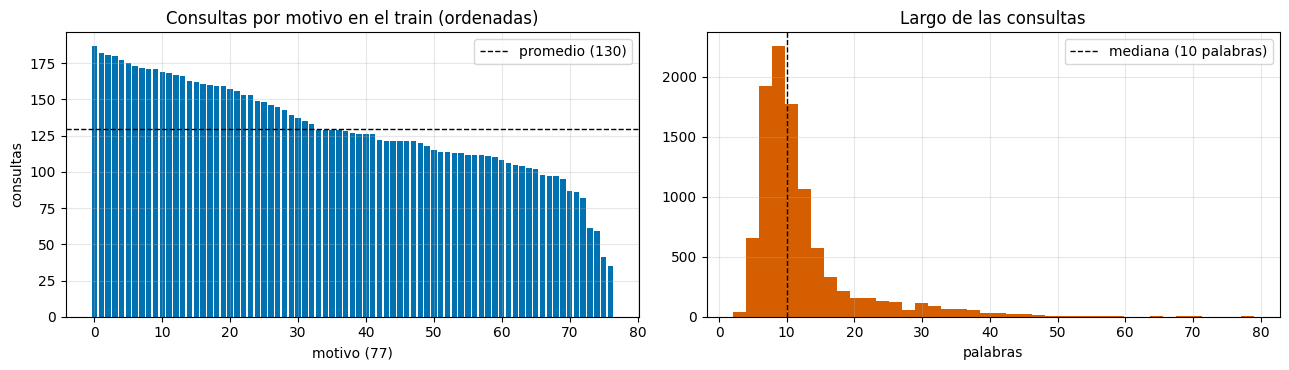

Motivos con más consultas : {'card_payment_fee_charged': 187, 'direct_debit_payment_not_recognised': 182, 'balance_not_updated_after_cheque_or_cash_deposit': 181}
Motivos con menos consultas: {'card_acceptance': 59, 'virtual_card_not_working': 41, 'contactless_not_working': 35}
En el test oficial: [40] consultas por motivo (balanceado)


In [4]:
por_clase = train_completo["category"].value_counts()
palabras = train_completo["text"].str.split().str.len()

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
ejes[0].bar(range(len(por_clase)), por_clase.values, color="#0072B2")
ejes[0].axhline(por_clase.mean(), color="black", ls="--", lw=1, label=f"promedio ({por_clase.mean():.0f})")
ejes[0].set_title("Consultas por motivo en el train (ordenadas)")
ejes[0].set_xlabel("motivo (77)"); ejes[0].set_ylabel("consultas"); ejes[0].legend()
ejes[1].hist(palabras, bins=40, color="#D55E00")
ejes[1].axvline(palabras.median(), color="black", ls="--", lw=1, label=f"mediana ({palabras.median():.0f} palabras)")
ejes[1].set_title("Largo de las consultas"); ejes[1].set_xlabel("palabras"); ejes[1].legend()
for eje in ejes:
    eje.grid(alpha=0.3)
fig.tight_layout()
plt.savefig(DIR_FIGURAS / "exploracion.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Motivos con más consultas : {por_clase.head(3).to_dict()}")
print(f"Motivos con menos consultas: {por_clase.tail(3).to_dict()}")
print(f"En el test oficial: {test['category'].value_counts().unique().tolist()} consultas por motivo (balanceado)")

**Lo que dice la exploración:**

- **Datos limpios:** sin nulos y sin consultas repetidas entre train y test.
- **Textos cortos:** la mitad de las consultas tiene 10 palabras o menos. Hay poco contexto en cada una, y por eso el orden de las palabras ("not received" vs "received") importa.
- **El train está desbalanceado (35 a 187 consultas por motivo), pero el test está perfectamente balanceado (40 por motivo).** Por eso, además del accuracy, se reporta el **F1 macro**, que pesa igual a todos los motivos: un modelo que solo acierte los motivos frecuentes no se ve bien con esa métrica.
- Hay **77 clases muy parecidas entre sí** (por ejemplo, varios motivos sobre transferencias o sobre tarjetas). Es un problema de clasificación fino, no trivial.

**Partición:** el test oficial queda cerrado hasta el final. La validación se separa del train oficial (15%, estratificada).

In [5]:
(loader_train, loader_val, loader_test), info, vectorizador = preparar_datos(config)
print(f"Train: {info['n_train']:,} | Validación: {info['n_val']:,} | Test: {info['n_test']:,}")

Train: 8,502 | Validación: 1,501 | Test: 3,080


## 3. Del texto a números: TF-IDF

Una red neuronal solo entiende números. Para esta entrega cada consulta se representa con **TF-IDF**: un vector con una posición por cada palabra (o par de palabras) del vocabulario, cuyo valor es alto si el término aparece en la consulta y es poco común en el resto. Es una representación simple pero fuerte para textos cortos, y es la base contra la que después se van a comparar las *embeddings*.

- **Unigramas y bigramas:** "card" y "not arrived" como términos, para captar algo de orden.
- **`min_df=2`:** un término tiene que aparecer en al menos 2 consultas del train (se descartan errores de tipeo y palabras únicas).
- **Ajustado solo con el train:** el vocabulario y los pesos IDF no ven validación ni test (es el mismo principio que el `StandardScaler` en tablas).
- La matriz se guarda **dispersa** (casi todo son ceros) y cada batch se convierte a denso recién al entrar al modelo.

In [6]:
lote_x, lote_y = next(iter(loader_train))
print(f"Tamaño del vocabulario: {info['n_variables']:,} términos")
print(f"Un batch: X {tuple(lote_x.shape)} {lote_x.dtype} | y {tuple(lote_y.shape)} {lote_y.dtype}")
print(f"Términos distintos de cero por consulta (promedio en el batch): {(lote_x > 0).sum(dim=1).float().mean():.1f}")

ejemplo = "I am still waiting on my card"
vector = vectorizador.transform([ejemplo])
terminos = vectorizador.get_feature_names_out()
pesos = sorted(zip(vector.indices, vector.data), key=lambda t: -t[1])
print(f"\n'{ejemplo}' -> {vector.nnz} términos con peso:")
for indice, peso in pesos:
    print(f"   {terminos[indice]!r:<20} {peso:.3f}")

Tamaño del vocabulario: 9,232 términos
Un batch: X (64, 9232) torch.float32 | y (64,) torch.int64
Términos distintos de cero por consulta (promedio en el batch): 18.4

'I am still waiting on my card' -> 11 términos con peso:
   'waiting on'         0.463
   'am still'           0.420
   'still waiting'      0.409
   'waiting'            0.355
   'still'              0.268
   'on my'              0.257
   'am'                 0.253
   'on'                 0.215
   'my card'            0.187
   'card'               0.146
   'my'                 0.105


Cada consulta activa solo unas decenas de términos entre miles: por eso conviene guardar la matriz dispersa. En el ejemplo, palabras frecuentes en todas las consultas ("my", "am") pesan menos que las específicas ("waiting", "still waiting").

## 4. Arquitectura

Dos modelos en `src/pipeline/modelos.py`, los dos heredan de `nn.Module`:

- **`ClasificadorLineal`**: una sola capa `nn.Linear(vocabulario, 77)`. Es una regresión logística multiclase: el **baseline**.
- **`ClasificadorMLP`**: `vocabulario → 256 → 77` con ReLU y **dropout de 0.3** (apaga al azar el 30% de las neuronas en cada paso de entrenamiento, para que la red no dependa de pocos términos y sobreajuste menos).

Los dos devuelven **logits crudos**: `nn.CrossEntropyLoss` aplica el Softmax adentro.

In [7]:
for arquitectura in ["lineal", "mlp"]:
    modelo = construir_modelo(replace(config, arquitectura=arquitectura), info["n_variables"], info["n_clases"]).to(dispositivo)
    salida = modelo(lote_x.to(dispositivo))          # prueba de humo: un batch real por el modelo
    print(f"--- {arquitectura}: {contar_parametros(modelo):,} parámetros | "
          f"entrada {tuple(lote_x.shape)} -> salida {tuple(salida.shape)}")
    print(modelo)

--- lineal: 710,941 parámetros | entrada (64, 9232) -> salida (64, 77)
ClasificadorLineal(
  (capa): Linear(in_features=9232, out_features=77, bias=True)
)
--- mlp: 2,383,437 parámetros | entrada (64, 9232) -> salida (64, 77)
ClasificadorMLP(
  (red): Sequential(
    (0): Linear(in_features=9232, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=77, bias=True)
  )
)


La **prueba de humo** confirma las dimensiones antes de entrenar: entran 64 consultas como vectores TF-IDF y salen 64 filas con 77 logits, uno por motivo.

## 5. Elección del learning rate

Se prueban tres órdenes de magnitud con el MLP, todo lo demás fijo, comparando la **loss de validación** (nunca la de test).

,mejor época,épocas corridas,mejor val loss,val accuracy,val F1 macro
learning_rate,,,,,
0.000100,30,30,0.7964,0.867,0.851
0.001000,17,22,0.3796,0.888,0.889
0.010000,3,8,0.4308,0.876,0.876


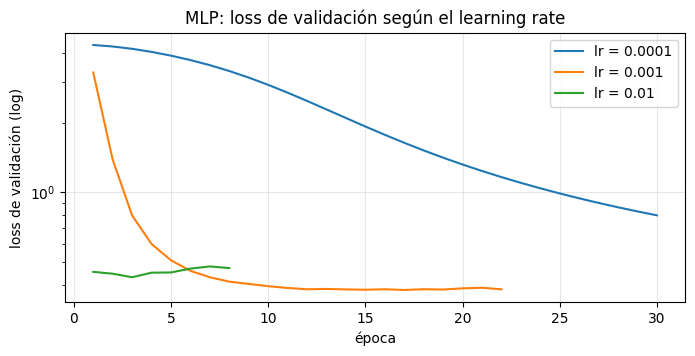

In [8]:
resultados_lr, curvas_lr = [], {}
for lr in [1e-4, 1e-3, 1e-2]:
    cfg = replace(config, learning_rate=lr)
    fijar_semilla(cfg.semilla)                                   # mismos pesos iniciales para cada lr
    loaders, _, _ = preparar_datos(cfg)
    modelo = construir_modelo(cfg, info["n_variables"], info["n_clases"])
    modelo, historial, resumen = entrenar(modelo, loaders[0], loaders[1], cfg, dispositivo, verbose=False)
    mejor = historial[resumen["mejor_epoca"] - 1]
    curvas_lr[lr] = [h["val_loss"] for h in historial]
    resultados_lr.append({"learning_rate": lr, "mejor época": resumen["mejor_epoca"],
                          "épocas corridas": resumen["epocas_corridas"], "mejor val loss": resumen["mejor_val_loss"],
                          "val accuracy": mejor["val_accuracy"], "val F1 macro": mejor["val_f1_macro"]})

tabla_lr = pd.DataFrame(resultados_lr).set_index("learning_rate")
display(tabla_lr.style.format({"mejor val loss": "{:.4f}", "val accuracy": "{:.3f}", "val F1 macro": "{:.3f}"}))

plt.figure(figsize=(8, 3.5))
for lr, curva in curvas_lr.items():
    plt.plot(range(1, len(curva) + 1), curva, label=f"lr = {lr:g}")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("loss de validación (log)")
plt.title("MLP: loss de validación según el learning rate"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(DIR_FIGURAS / "comparacion_learning_rate.png", dpi=120, bbox_inches="tight")
plt.show()

**Se elige `learning_rate = 0.001`** (el valor por defecto de Adam), que logra la menor loss de validación:

- **0.0001** es demasiado lento: en 30 épocas la loss sigue bajando y queda lejos.
- **0.01** baja muy rápido, toca su mínimo en la época 3 y después la validación empeora: el *early stopping* lo corta enseguida.
- **0.001** llega más abajo que los dos.

## 6. Entrenamiento y validación del modelo final

En cada batch: `zero_grad()` → forward → loss → `backward()` → `step()` (`src/pipeline/entrenamiento.py`). Al final de cada época se evalúa en validación con `model.eval()` y `torch.no_grad()`, y se registran **loss, accuracy y F1 macro**. Se guardan los pesos de la época con menor loss de validación (*early stopping* con paciencia de 5 épocas).

Época   1/30 | train loss 4.0092 acc 0.308 | val loss 3.2863 acc 0.607 f1 0.534


Época   2/30 | train loss 2.1864 acc 0.749 | val loss 1.3841 acc 0.811 f1 0.766


Época   4/30 | train loss 0.4746 acc 0.934 | val loss 0.5992 acc 0.872 f1 0.866


Época   6/30 | train loss 0.2083 acc 0.973 | val loss 0.4588 acc 0.887 f1 0.885


Época   8/30 | train loss 0.1148 acc 0.985 | val loss 0.4123 acc 0.889 f1 0.888


Época  10/30 | train loss 0.0703 acc 0.992 | val loss 0.3942 acc 0.889 f1 0.889


... (2 outputs left out)

Época  16/30 | train loss 0.0266 acc 0.998 | val loss 0.3824 acc 0.885 f1 0.886


Época  18/30 | train loss 0.0197 acc 0.998 | val loss 0.3825 acc 0.883 f1 0.885


Época  20/30 | train loss 0.0155 acc 0.999 | val loss 0.3858 acc 0.887 f1 0.888


Época  22/30 | train loss 0.0126 acc 0.999 | val loss 0.3822 acc 0.885 f1 0.886
Early stopping en la época 22: 5 épocas sin mejorar la validación
Mejor época: 17 (val loss 0.3796) | 37.4 s


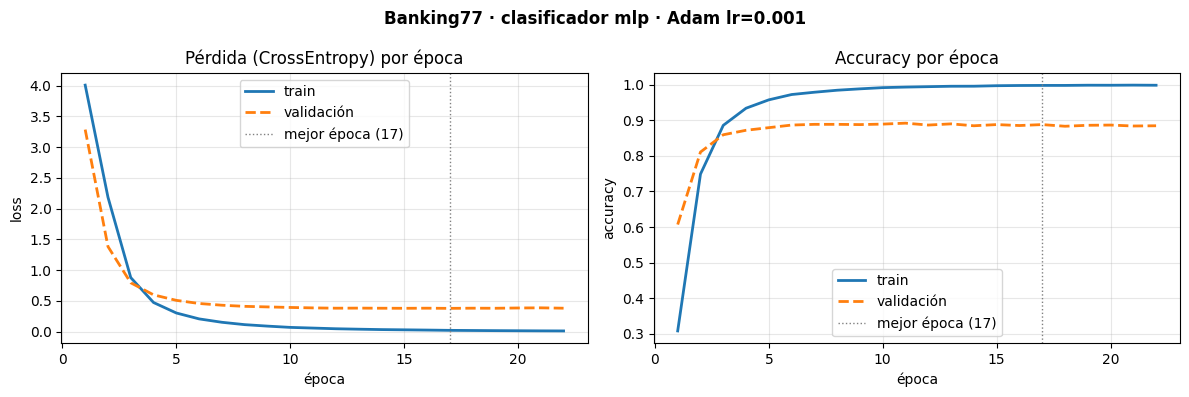

In [9]:
fijar_semilla(config.semilla)
(loader_train, loader_val, loader_test), info, vectorizador = preparar_datos(config)
modelo_mlp = construir_modelo(config, info["n_variables"], info["n_clases"])
modelo_mlp, historial_mlp, resumen_mlp = entrenar(modelo_mlp, loader_train, loader_val, config, dispositivo, cada=2)

graficar_curvas(historial_mlp, resumen_mlp["mejor_epoca"], f"Banking77 · clasificador mlp · Adam lr={config.learning_rate:g}",
                DIR_FIGURAS / "curvas_mlp.png")
plt.show()

In [10]:
df_mlp = pd.DataFrame(historial_mlp).set_index("epoca")
puntos = sorted({1, 3, 5, 10, resumen_mlp["mejor_epoca"], len(df_mlp)})
display(df_mlp.loc[puntos].style.format("{:.4f}"))

mejor = df_mlp.loc[resumen_mlp["mejor_epoca"]]
print(f"En la mejor época ({resumen_mlp['mejor_epoca']}): brecha de loss train-validación {mejor['val_loss'] - mejor['train_loss']:.3f} | "
      f"brecha de accuracy {mejor['train_accuracy'] - mejor['val_accuracy']:.3f}")

,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro
epoca,,,,,
1,4.0092,0.3077,3.2863,0.6069,0.5336
3,0.8798,0.8859,0.7954,0.8594,0.8393
5,0.3043,0.9577,0.5098,0.8794,0.8789
10,0.0703,0.9920,0.3942,0.8894,0.8893
17,0.0220,0.9982,0.3796,0.8881,0.8885
22,0.0126,0.9987,0.3822,0.8847,0.8860


En la mejor época (17): brecha de loss train-validación 0.358 | brecha de accuracy 0.110


**Lectura de la curva de pérdida:**

- **La pérdida bajó**: en train de forma sostenida durante todas las épocas, y en validación hasta la mejor época, con la caída fuerte en las primeras 5.
- **Después la validación se estanca y empieza a subir levemente**, mientras el train sigue bajando: el modelo empieza a memorizar el train (sobreajuste). El *early stopping* lo detecta y vuelve a los pesos de la mejor época.
- La brecha entre train y validación es grande en accuracy: con ~9.000 términos y solo ~110 consultas por motivo, el MLP tiene capacidad de sobra para memorizar. El dropout la achica, pero no la elimina. Es la principal limitación de este baseline, y lo que las *embeddings* de la próxima entrega deberían mejorar (representaciones más compactas y que generalizan entre sinónimos).

## 7. Comparación con el baseline lineal

Para que la comparación sea justa, el lineal usa **su propio** mejor learning rate (0.01) y más épocas (60), porque converge más lento.

In [11]:
config_lineal = replace(config, arquitectura="lineal", learning_rate=1e-2, epocas=60)
fijar_semilla(config_lineal.semilla)
loaders_lineal, _, _ = preparar_datos(config_lineal)
modelo_lineal = construir_modelo(config_lineal, info["n_variables"], info["n_clases"])
modelo_lineal, historial_lineal, resumen_lineal = entrenar(modelo_lineal, loaders_lineal[0], loaders_lineal[1],
                                                           config_lineal, dispositivo, verbose=False)

criterio = nn.CrossEntropyLoss()
filas = []
for nombre, modelo, resumen in [("Lineal (baseline)", modelo_lineal, resumen_lineal), ("MLP", modelo_mlp, resumen_mlp)]:
    val = evaluar(modelo, loader_val, criterio, dispositivo)
    filas.append({"modelo": nombre, "parámetros": contar_parametros(modelo), "mejor época": resumen["mejor_epoca"],
                  "val loss": val["loss"], "val accuracy": val["accuracy"], "val F1 macro": val["f1_macro"]})
comparacion = pd.DataFrame(filas).set_index("modelo")
display(comparacion.style.format({"parámetros": "{:,}", "val loss": "{:.4f}", "val accuracy": "{:.3f}", "val F1 macro": "{:.3f}"}))

,parámetros,mejor época,val loss,val accuracy,val F1 macro
modelo,,,,,
Lineal (baseline),"710,941",41,0.4609,0.872,0.868
MLP,"2,383,437",17,0.3796,0.888,0.889


El MLP mejora al lineal en todas las métricas de validación: la capa oculta combina términos ("card" + "not arrived" vs "card" + "declined") de una forma que una sola capa lineal no puede. La mejora es moderada: con TF-IDF, buena parte de la información ya está en qué palabras aparecen. Un baseline sirve justamente para eso: saber cuánto aporta la complejidad extra.

## 8. Evaluación final en test

Recién ahora se usa el test oficial, una sola vez, con los pesos de la mejor época de cada modelo.

In [12]:
test_mlp = evaluar(modelo_mlp, loader_test, criterio, dispositivo)
test_lineal = evaluar(modelo_lineal, loader_test, criterio, dispositivo)
print(f"MLP    -> test loss {test_mlp['loss']:.4f} | accuracy {test_mlp['accuracy']:.3f} | F1 macro {test_mlp['f1_macro']:.3f}")
print(f"Lineal -> test loss {test_lineal['loss']:.4f} | accuracy {test_lineal['accuracy']:.3f} | F1 macro {test_lineal['f1_macro']:.3f}")

modelo_mlp.eval()
pred, real = [], []
with torch.no_grad():
    for xb, yb in loader_test:
        pred.append(modelo_mlp(xb.to(dispositivo)).argmax(dim=1).cpu())
        real.append(yb)
pred, real = torch.cat(pred).numpy(), torch.cat(real).numpy()
clases = info["clases"]

reporte = pd.DataFrame(classification_report(real, pred, target_names=clases, output_dict=True)).T.iloc[:-3]
print("\nLos 5 motivos con peor F1 en test:")
display(reporte.sort_values("f1-score").head(5)[["precision", "recall", "f1-score"]].round(3))

matriz = confusion_matrix(real, pred)
np.fill_diagonal(matriz, 0)
pares = sorted(((matriz[i, j], clases[i], clases[j]) for i in range(len(clases)) for j in range(len(clases)) if matriz[i, j] > 0),
               reverse=True)[:8]
print("Confusiones más frecuentes (real -> predicho):")
display(pd.DataFrame(pares, columns=["errores", "motivo real", "predicho como"]))

MLP    -> test loss 0.3478 | accuracy 0.898 | F1 macro 0.899
Lineal -> test loss 0.4564 | accuracy 0.874 | F1 macro 0.875

Los 5 motivos con peor F1 en test:


,precision,recall,f1-score
balance_not_updated_after_bank_transfer,0.707,0.725,0.716
pending_transfer,0.763,0.725,0.744
verify_my_identity,0.763,0.725,0.744
transfer_not_received_by_recipient,0.733,0.825,0.776
card_not_working,0.673,0.925,0.779


Confusiones más frecuentes (real -> predicho):


,errores,motivo real,predicho como
0,7,verify_my_identity,why_verify_identity
1,5,unable_to_verify_identity,verify_my_identity
2,5,get_physical_card,pin_blocked
3,5,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient
4,4,why_verify_identity,verify_my_identity
5,4,top_up_failed,top_up_reverted
6,4,pending_transfer,balance_not_updated_after_bank_transfer
7,4,declined_transfer,declined_card_payment


**Análisis de errores:** el test está balanceado (40 consultas por motivo), así que accuracy y F1 macro casi coinciden. Los errores **no son al azar**: se concentran en pares de motivos que **a un humano también le costaría distinguir**, porque hablan de lo mismo con matices:

- *verificar mi identidad* vs *por qué tengo que verificarla* vs *no puedo verificarla*;
- *recarga fallida* vs *recarga revertida*;
- *transferencia pendiente* vs *saldo no actualizado después de una transferencia*;
- *transferencia rechazada* vs *pago con tarjeta rechazado*.

Un caso curioso es *get_physical_card* → *pin_blocked*: en este dataset, casi todas las consultas de "obtener la tarjeta física" en realidad preguntan por el PIN ("Is the PIN delivered separately?"), así que la confusión viene en parte de cómo se etiquetó el dataset.

Con TF-IDF el modelo ve las mismas palabras en las dos clases y no capta el matiz. Ese es el margen de mejora para las *embeddings* y los Transformers.

Para el negocio, esto también dice algo: si dos motivos se confunden tanto, quizás convenga derivarlos al mismo equipo o fusionarlos en el ruteo.

In [13]:
def predecir(texto, top=3):
    # Clasifica una consulta nueva y devuelve los motivos más probables
    vector = torch.from_numpy(vectorizador.transform([texto]).toarray().astype(np.float32)).to(dispositivo)
    modelo_mlp.eval()
    with torch.no_grad():
        probabilidades = torch.softmax(modelo_mlp(vector), dim=1)[0].cpu()
    mejores = torch.topk(probabilidades, top)
    return [(clases[i], round(p.item(), 3)) for p, i in zip(mejores.values, mejores.indices)]


for consulta in ["My card still hasn't arrived and it's been two weeks",
                 "Why was I charged an extra fee for withdrawing cash?",
                 "I think someone stole my phone and is using my account"]:
    print(f"{consulta!r}\n   -> {predecir(consulta)}")

"My card still hasn't arrived and it's been two weeks"
   -> [('card_arrival', 0.997), ('reverted_card_payment?', 0.001), ('transfer_not_received_by_recipient', 0.001)]
'Why was I charged an extra fee for withdrawing cash?'
   -> [('cash_withdrawal_charge', 0.999), ('transfer_fee_charged', 0.001), ('card_payment_fee_charged', 0.0)]
'I think someone stole my phone and is using my account'
   -> [('lost_or_stolen_phone', 0.895), ('compromised_card', 0.047), ('cash_withdrawal_not_recognised', 0.046)]


Así se usaría en producción: entra una consulta nueva y el modelo devuelve los motivos más probables con su probabilidad. Si la probabilidad del primero es baja, la consulta se puede mandar a revisión humana en lugar de derivarla automáticamente.

## 9. Conclusiones

1. **El pipeline funciona de punta a punta y es reproducible:** semillas fijas, dispositivo automático, datos descargados y verificados por hash, TF-IDF ajustado sin fuga, entrenamiento con Adam y `backward()`, validación por época con loss, accuracy y F1 macro, early stopping y evaluación final en test.
2. **Learning rate elegido: 0.001**, el que minimiza la loss de validación.
3. **La pérdida bajó** en train y validación hasta la mejor época; después aparece sobreajuste, que el early stopping corta.
4. **El MLP supera al baseline lineal**, y los dos dejan una vara clara (cerca de 90% de accuracy en test) para las próximas entregas.

**Próximos pasos del proyecto:** reemplazar TF-IDF por *embeddings* aprendidas, después ajustar un Transformer preentrenado, traducir las consultas al español para evaluar el modelo en nuestro idioma y, por último, generar una respuesta sugerida para cada consulta.